# 01 — Regressão linear

**CMP263 (PPGC/UFRGS, 2026/2)** · Grupo: Artur Mariano, Emerson Herrera e Yaser Husein

**Pergunta:** as características estruturais de uma escola (infraestrutura, rede, localização, tamanho, docentes) predizem o desempenho médio dos seus alunos no ENEM 2025?

Este notebook ajusta o modelo mais simples da comparação: **regressão linear por mínimos quadrados** (`sklearn.linear_model.LinearRegression`), sem regularização e sem ajuste de hiperparâmetros. Os outros algoritmos usam **os mesmos dados, o mesmo pré-processamento (`build_preprocessor`) e as mesmas dobras (`assign_folds`)**, importados de `src/enem_school/preprocessing.py`, para que os números sejam comparáveis.

| Item | Escolha |
|---|---|
| Unidade | escola com ≥ 10 candidatos presentes nas 4 provas (23.374 escolas) |
| Alvo | `nota_media`: média, por escola, da média das 5 notas |
| Atributos | 43 atributos do Censo Escolar 2024 + 2 indicadores do código 88888 (`src/enem_school/preprocessing.py`) |
| Validação | 5 dobras fixas por município (`assign_folds`: `GroupKFold` embaralhado com `config.SEED`) |
| Métricas | RMSE, MAE (em pontos do ENEM) e R² |

### Reprodutibilidade

- Os dados vêm de `scripts/build_dataset.py`, que registra a URL e o SHA-256 de cada arquivo do INEP. A seção 2 confere esses hashes.
- As versões das bibliotecas estão fixadas em `uv.lock` / `requirements.txt`. A última seção imprime as versões usadas na execução.
- As dobras vêm de `assign_folds`, que embaralha os municípios com `config.SEED`: todos os notebooks usam exatamente as mesmas dobras.
- Para rodar de novo: **Kernel → Restart & Run All** (local) ou **Ambiente de execução → Executar tudo** (Colab). O notebook deve rodar do início ao fim sem intervenção manual.

## 1. Ambiente

A célula abaixo funciona **localmente** e **no Google Colab**:

- **Local:** rode a partir da raiz do repositório, depois de `uv sync --group notebooks`, e abra com `uv run jupyter lab`.
- **Colab:** a célula clona o repositório e instala as versões fixadas em `requirements.txt`. Se o Colab avisar que precisa reiniciar a sessão (por trocar a versão do pandas/numpy), reinicie e rode tudo de novo.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/emersonheto/enem-school-performance.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    repo = Path("/content/enem-school-performance")
    if not repo.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo)], check=True)
    os.chdir(repo)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

# Raiz do repositório: funciona com o notebook aberto em notebooks/ ou na raiz.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
print("Raiz do repositório:", ROOT.name)
print("Colab:", IN_COLAB)

Raiz do repositório: enem-school-performance
Colab: False


In [2]:
import json
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import PredefinedSplit, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder

from enem_school import config
from enem_school.preprocessing import assign_folds, build_preprocessor, feature_columns

random.seed(config.SEED)
np.random.seed(config.SEED)
pd.set_option("display.precision", 2)

RESULTS_DIR = config.REPORTS_DIR / "results"
FIGURES_DIR = config.REPORTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 2. Dados

A tabela por escola é gerada por `scripts/build_dataset.py`. Se ela ainda não existir (por exemplo, numa sessão nova do Colab), a célula abaixo roda o script, que **baixa cerca de 1 GB do INEP** e leva alguns minutos.

Em seguida conferimos o SHA-256 dos arquivos brutos registrados nos metadados. Se o INEP republicar os microdados, os hashes mudam e a célula falha. Assim, nunca comparamos sem perceber resultados obtidos com dados diferentes.

In [3]:
if not config.SCHOOL_TABLE.exists():
    subprocess.run([sys.executable, str(ROOT / "scripts" / "build_dataset.py")], check=True, cwd=ROOT)

EXPECTED_SHA256 = {
    "enem": "b8d3e72cbf387ee08f18d552367005429017d43eea1f6d4b9bafe1d83a116071",
    "censo": "ae29d81d45ddecef59e11eda39788cbfd30dfa1cc71be9d29f23051fc2d640db",
}
metadata = json.loads(config.SCHOOL_TABLE_METADATA.read_text(encoding="utf-8"))
for source, expected in EXPECTED_SHA256.items():
    assert metadata["sources"][source]["sha256"] == expected, f"{source}: arquivo do INEP diferente do usado no trabalho"

schools = pd.read_parquet(config.SCHOOL_TABLE)
assert len(schools) == metadata["joined_schools"] == 23_374
print(f"{len(schools):,} escolas, {schools.shape[1]} colunas")
schools.head()

23,374 escolas, 50 colunas


,CO_ESCOLA,n_alunos,nota_media,IN_AGUA_POTAVEL,IN_AGUA_REDE_PUBLICA,IN_ENERGIA_REDE_PUBLICA,IN_ESGOTO_REDE_PUBLICA,IN_LIXO_SERVICO_COLETA,IN_BANHEIRO,IN_BANHEIRO_PNE,...,QT_SALAS_UTILIZA_CLIMATIZADAS,QT_DESKTOP_ALUNO,QT_COMP_PORTATIL_ALUNO,TP_DEPENDENCIA,TP_LOCALIZACAO,TP_LOCALIZACAO_DIFERENCIADA,CO_REGIAO,SG_UF,CO_MUNICIPIO,CO_UF
0,11000058,119,644.81,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,38.0,40.0,0.0,4,1,0.0,1,RO,1100205,11
1,11000198,51,590.26,1.0,0.0,1.0,1.0,1.0,1.0,1.0,...,44.0,72.0,23.0,4,1,0.0,1,RO,1100205,11
2,11000252,44,598.53,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,25.0,0.0,0.0,4,1,0.0,1,RO,1100205,11
3,11000260,127,557.12,1.0,0.0,1.0,1.0,1.0,1.0,1.0,...,33.0,0.0,0.0,2,1,0.0,1,RO,1100205,11
4,11000317,34,460.84,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,17.0,19.0,5.0,2,1,0.0,1,RO,1100205,11


## 3. Atributos, alvo e dobras

Todo o pré-processamento é **compartilhado** e vem de `src/enem_school/preprocessing.py`. Este notebook só escolhe a variante de atributos:

| Variante | Atributos | Pergunta |
|---|---|---|
| **A** | 43 do Censo (sem `CO_REGIAO`, que repete a UF, e sem `QT_TUR_MED`, que repete as matrículas) | modelo completo |
| **B** | A sem `TP_DEPENDENCIA` | a estrutura física prediz sem saber a rede? |
| **C** | B sem `IN_ALIMENTACAO` | e sem a merenda, quase exclusiva da rede pública? |

`CO_MUNICIPIO` **não é atributo**. Ele só define as dobras: `assign_folds` coloca todas as escolas de um município na mesma dobra, com `config.SEED`.

In [4]:
TARGET = config.TARGET

y = schools[TARGET].to_numpy()
folds = assign_folds(schools)

for variant in ("A", "B", "C"):
    print(f"Variante {variant}: {len(feature_columns(variant))} atributos")
print(f"Municípios: {schools['CO_MUNICIPIO'].nunique():,}; escolas por dobra: {folds.value_counts().sort_index().tolist()}")
print(f"Alvo: média {y.mean():.1f}, desvio {y.std(ddof=1):.1f}")

Variante A: 43 atributos
Variante B: 42 atributos
Variante C: 41 atributos
Municípios: 5,201; escolas por dobra: [3989, 4368, 5062, 4718, 5237]
Alvo: média 524.7, desvio 62.4


## 4. Pipeline

`build_preprocessor(variante)` devolve um `Pipeline` do scikit-learn. Tudo o que **aprende com os dados** fica dentro dele, então em cada dobra medianas, modas, médias, desvios e categorias são calculados **só no treino**:

| Passo | O que faz | Por quê |
|---|---|---|
| Código 88888 | vira faltante + coluna indicadora `*_extremo` | no Censo, 88888 marca "valor extremo" (15 escolas), não uma contagem real |
| Contagens (`QT_*`) | mediana → `log1p` → padronização | as contagens são muito assimétricas (até 18); o log reduz o peso das escolas gigantes |
| Binários (`IN_*` + indicadores) | moda, **sem padronizar** | já são 0/1; padronizar daria peso enorme aos binários raros em kNN e SVR |
| Categóricos | moda → one-hot; categoria não vista → zeros | `TP_DEPENDENCIA = 4` é uma categoria, não um número |

O regressor entra como último passo. Os baselines são os mesmos de antes:

| Modelo | Atributos | Para quê |
|---|---|---|
| **Baseline: média** | nenhum | erro de quem chuta a média geral |
| **Baseline: rede** | só `TP_DEPENDENCIA` | equivale a prever a média de cada rede |
| **Linear A / B / C** | variantes acima | quanto a estrutura acrescenta, com e sem os *proxies* da rede |

In [5]:
def make_model(variant: str) -> Pipeline:
    # Pré-processamento compartilhado + regressão linear.
    return Pipeline([("preprocess", build_preprocessor(variant)), ("regressor", LinearRegression())])


baseline_rede = make_pipeline(OneHotEncoder(handle_unknown="ignore", sparse_output=False), LinearRegression())

models = {
    "Baseline: média": (DummyRegressor(strategy="mean"), ["TP_DEPENDENCIA"]),  # ignora X
    "Baseline: rede": (baseline_rede, ["TP_DEPENDENCIA"]),
    "Linear A (com rede)": (make_model("A"), feature_columns("A")),
    "Linear B (sem rede)": (make_model("B"), feature_columns("B")),
    "Linear C (sem rede e sem merenda)": (make_model("C"), feature_columns("C")),
}
models["Linear A (com rede)"][0]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('extreme_values', ...), ('columns', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function mar...t 0x1197300e0>
,"fe

## 5. Validação cruzada agrupada por município

`PredefinedSplit(folds)` usa as dobras de `assign_folds`: todas as escolas de um município caem na mesma dobra. Isso impede que o modelo seja testado em escolas vizinhas das que viu no treino, o que inflaria as métricas, já que escolas da mesma cidade se parecem. Os outros notebooks devem montar o `cv` exatamente assim.

In [6]:
cv = PredefinedSplit(folds)
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

fold_rows = []
for name, (model, columns) in models.items():
    scores = cross_validate(model, schools[columns], y, cv=cv, scoring=SCORING)
    for fold in range(cv.get_n_splits()):
        fold_rows.append(
            {
                "modelo": name,
                "dobra": fold + 1,
                "rmse": -scores["test_rmse"][fold],
                "mae": -scores["test_mae"][fold],
                "r2": scores["test_r2"][fold],
            }
        )

folds = pd.DataFrame(fold_rows)
summary = folds.groupby("modelo", sort=False)[["rmse", "mae", "r2"]].agg(["mean", "std"]).round(3)
summary

rmse          mae              r2  \
                                    mean   std   mean   std      mean   
modelo                                                                  
Baseline: média                    62.41  1.63  50.25  1.36 -3.00e-03   
Baseline: rede                     39.73  1.04  30.73  0.88  5.94e-01   
Linear A (com rede)                34.32  0.93  26.15  0.54  6.97e-01   
Linear B (sem rede)                37.40  0.81  28.30  0.55  6.40e-01   
Linear C (sem rede e sem merenda)  43.97  1.34  33.63  0.93  5.02e-01   

                                             
                                        std  
modelo                                       
Baseline: média                    2.00e-03  
Baseline: rede                     4.00e-03  
Linear A (com rede)                1.20e-02  
Linear B (sem rede)                8.00e-03  
Linear C (sem rede e sem merenda)  1.00e-02

In [7]:
folds.to_csv(RESULTS_DIR / "linear_regression_folds.csv", index=False)
summary.to_csv(RESULTS_DIR / "linear_regression_summary.csv")
print("Salvo em", RESULTS_DIR.relative_to(ROOT))

Salvo em reports/results


### Como ler

- **RMSE/MAE** estão em pontos do ENEM. O baseline da média tem RMSE ≈ desvio do alvo (≈ 62). Qualquer modelo útil precisa ficar abaixo disso.
- **Baseline: rede** mostra quanto a rede explica sozinha. O ganho do **Linear A** sobre ele é o que os demais atributos acrescentam.
- **Linear B** mostra quanto a estrutura física prediz sem saber a rede. Se B ficar perto de A, a informação da rede já está "escondida" nos outros atributos (por exemplo, `IN_ALIMENTACAO`, a merenda, é quase exclusiva da rede pública).
- **Linear C** tira também a merenda. Se a queda de B para C for grande, a merenda carregava boa parte da informação da rede.
- O desvio entre dobras indica a estabilidade da estimativa.

## 6. Coeficientes do modelo A

Para interpretar, ajustamos o modelo A em **todas** as escolas (a avaliação já foi feita na seção 5). Como as contagens são padronizadas e os binários não, os coeficientes estão em **unidades diferentes** e aparecem em dois gráficos:

- **Contagens:** pontos na nota por +1 desvio-padrão de `log(1 + contagem)`.
- **Binários:** pontos na nota por ter o item (0 → 1).

**Cuidados na leitura:**

- Coeficiente ≠ efeito causal. É associação condicional aos demais atributos.
- Atributos muito correlacionados (ex.: `IN_INTERNET` × `IN_BANDA_LARGA`) dividem o efeito entre si de forma instável, e podem aparecer com sinais opostos.
- Os coeficientes das categorias do one-hot não são identificáveis individualmente: cada bloco soma com o intercepto. Compare categorias **do mesmo atributo** entre si, nunca o valor isolado.

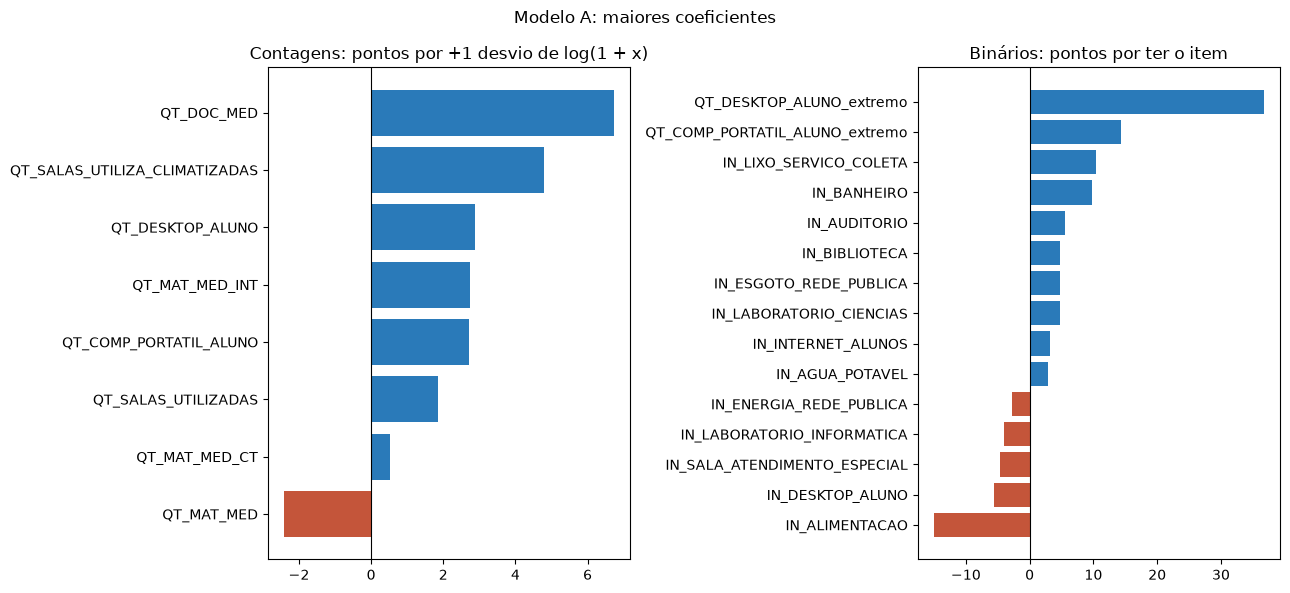

In [8]:
model_a = models["Linear A (com rede)"][0]
model_a.fit(schools[feature_columns("A")], y)

names = model_a.named_steps["preprocess"].get_feature_names_out()
coefficients = pd.Series(model_a.named_steps["regressor"].coef_, index=names)
blocks = {
    "Contagens: pontos por +1 desvio de log(1 + x)": coefficients.filter(regex="^counts__"),
    "Binários: pontos por ter o item": coefficients.filter(regex="^binaries__"),
}
coefficients.index = coefficients.index.str.replace(r"^(counts|binaries|categorical)__", "", regex=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, (title, block) in zip(axes, blocks.items()):
    block.index = block.index.str.replace(r"^(counts|binaries)__", "", regex=True)
    top = block.sort_values(key=abs, ascending=False).head(15).sort_values()
    ax.barh(top.index, top.values, color=np.where(top.values > 0, "#2a7ab9", "#c4553a"))
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(title)
fig.suptitle("Modelo A: maiores coeficientes")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "linreg_coefficients.png", dpi=150)
plt.show()

In [9]:
# Coeficientes da rede, relativos à rede estadual (a maior).
rede = coefficients.filter(like="TP_DEPENDENCIA_")
rede.index = rede.index.str.replace("TP_DEPENDENCIA_", "").map(
    {"1": "Federal", "2": "Estadual", "3": "Municipal", "4": "Privada"}
)
(rede - rede["Estadual"]).rename("diferença em relação à Estadual (pontos)").to_frame()

,diferença em relação à Estadual (pontos)
Federal,60.38
Estadual,0.00
Municipal,21.77
Privada,84.23


## 7. Resíduos (previsões fora da amostra)

`cross_val_predict` com o mesmo `cv` gera, para cada escola, a previsão do modelo treinado **sem a dobra dela**. Assim os resíduos refletem erro de generalização. Resíduo = observado − previsto, então resíduo positivo indica uma escola acima do que a estrutura prevê.

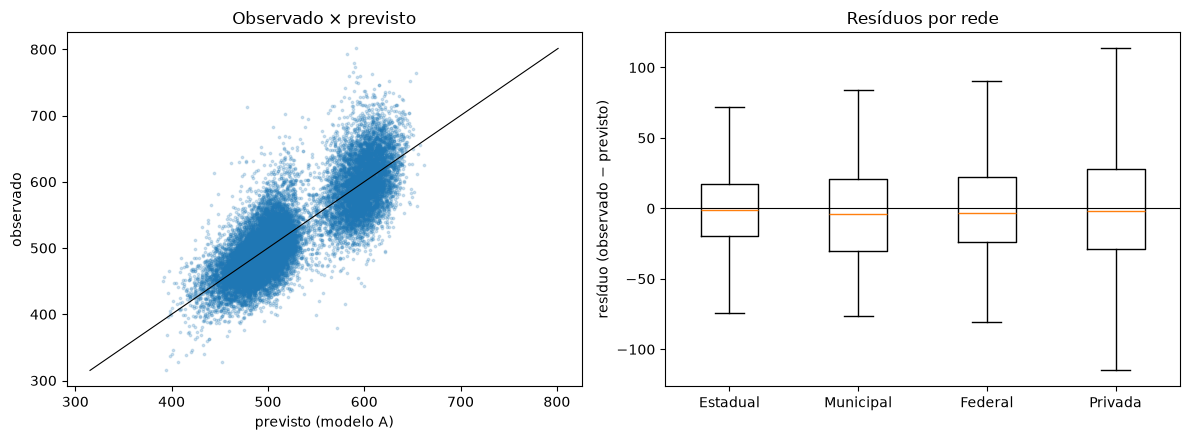

RMSE fora da amostra (todas as dobras juntas): 34.3


In [10]:
predicted = cross_val_predict(model_a, schools[feature_columns("A")], y, cv=cv)
residuals = y - predicted

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(predicted, y, s=3, alpha=0.2)
lims = [min(y.min(), predicted.min()), max(y.max(), predicted.max())]
axes[0].plot(lims, lims, color="black", linewidth=0.8)
axes[0].set_xlabel("previsto (modelo A)")
axes[0].set_ylabel("observado")
axes[0].set_title("Observado × previsto")

rede_label = schools["TP_DEPENDENCIA"].map({1: "Federal", 2: "Estadual", 3: "Municipal", 4: "Privada"})
order = ["Estadual", "Municipal", "Federal", "Privada"]
axes[1].boxplot([residuals[rede_label == r] for r in order], tick_labels=order, showfliers=False)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("resíduo (observado − previsto)")
axes[1].set_title("Resíduos por rede")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "linreg_residuals.png", dpi=150)
plt.show()

print(f"RMSE fora da amostra (todas as dobras juntas): {np.sqrt(np.mean(residuals**2)):.1f}")

## 8. Conclusões (preencher após rodar)

- [ ] Quanto o modelo A melhora sobre o baseline da rede?
- [ ] Qual a perda ao tirar a rede (A × B) e a merenda (B × C)?
- [ ] Quais atributos têm os maiores coeficientes, e eles fazem sentido?
- [ ] Há padrão nos resíduos (por rede, por faixa de nota) que sugira não linearidade? Isso motiva árvores, kNN e SVR.

**Próximos passos possíveis (fora do "mais simples"):** Ridge para lidar com a colinearidade, retirada dos 6 binários quase constantes.

## Ambiente de execução

Registro das versões usadas, para conferir com `uv.lock`.

In [11]:
import platform

import sklearn

print("Python      ", platform.python_version())
for lib in (np, pd, sklearn):
    print(f"{lib.__name__:<12}", lib.__version__)
print("Plataforma  ", platform.platform())

Python       3.12.13
numpy        2.5.4
pandas       3.0.6
sklearn      1.9.1
Plataforma   macOS-27.2-arm64-arm-64bit
